In [1]:
# plotting the bar plot data in a differnet way based on feedback

import pandas as pd 
import matplotlib.pyplot as plt 
import matplotlib.patches as mpatches
from matplotlib.colors import to_rgb, to_rgba

import seaborn as sns 
import numpy as np 
import scipy.stats 

from config import llm_review_path, supp_table_path
import copy 

data_output_path = llm_review_path + "source_data_csvs/"
panels_path = llm_review_path + "source_data_csvs/completed_panels/"



def mean_confidence_interval(data, confidence=0.95):
    a = 1.0 * np.array(data)
    n = len(a)
    m, se = np.mean(a), scipy.stats.sem(a)
    h = se * scipy.stats.t.ppf((1 + confidence) / 2.0, n - 1)
    return m, m - h, m + h


def p_val_to_stars(p):
    if p <= 0.001:
        return "***"
    if p <= 0.01:
        return "**"
    if p <= 0.05:
        return "*"
    return "ns"

In [2]:
model_to_display_a = {
    'ProtT5-XL (3B) UR50' : "ProtT5-XL",
     'ESM-2 (15B)' : "ESM-2\n15B",
     'ESM-2 (3B)': "ESM-2\n3B",
     'ESM-2 (650M)': "ESM-2\n650M",
     'ESM-2 (150M)': "ESM-2\n150M",
     'ESM-2 (35M)': "ESM-2\n35M",
     'ESM-2 (8M)' : "ESM-2\n8M",
     'ESM-1b': "ESM-1b\n650M",
     'ESM-1 (670M) UR50S': "ESM-1\n650M\nUR50S",
     'ESM-1 (670M) UR50D': "ESM-1\n650M\nUR50D",
     'ESM-1 (43M)': "ESM-1\n43M",
     'ESM-1 (85M)': "ESM-1\n85MM",
     'CARP (640M)': "CARP\n640M",
     'CARP (38M)': "CARP\n38M",
     'CARP (76M)': "CARP\n76M",
     'ESM-1v': "ESM-1v\n650M",
     'Progen2 (2.7B) UR90+BFD30': "Progen2\n2.7B",
     'Progen2 (764M) UR90+BFD30': "Progen2\n764M",
     'ProtBERT': "ProtBERT\n420M\nUR100",
     'ESM-1 (670M) UR100': "ESM-1\n650M\nUR100"
}

In [3]:
df = pd.read_csv(supp_table_path + "revisions/downstream_results.csv")

data_E3a = df.loc[
    (df["Task"] == "Solubility") & 
    (df["Pool Method"] == "mean_pooled") & 
    (df["Training Setup"] == "Downstream NN")
]


data_E3b = df.loc[
    (df["Task"] == "Subcellular Localization") & 
    (df["Pool Method"] == "mean_pooled") & 
    (df["Training Setup"] == "Downstream NN")
]

data_E3c = df.loc[
    (df["Task"] == "PPI Affinity") & 
    (df["Pool Method"] == "mean_pooled") & 
    (df["Training Setup"] == "Downstream NN")
]

data_E3d = df.loc[
    (df["Pool Method"] == "mean_pooled") & 
    (df["Training Setup"] == "Fine Tuned")
]



/tmp/ipykernel_1805228/2773452421.py:132: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")


Text(0.5, 1.0, 'Solubility - Mean Pooled')

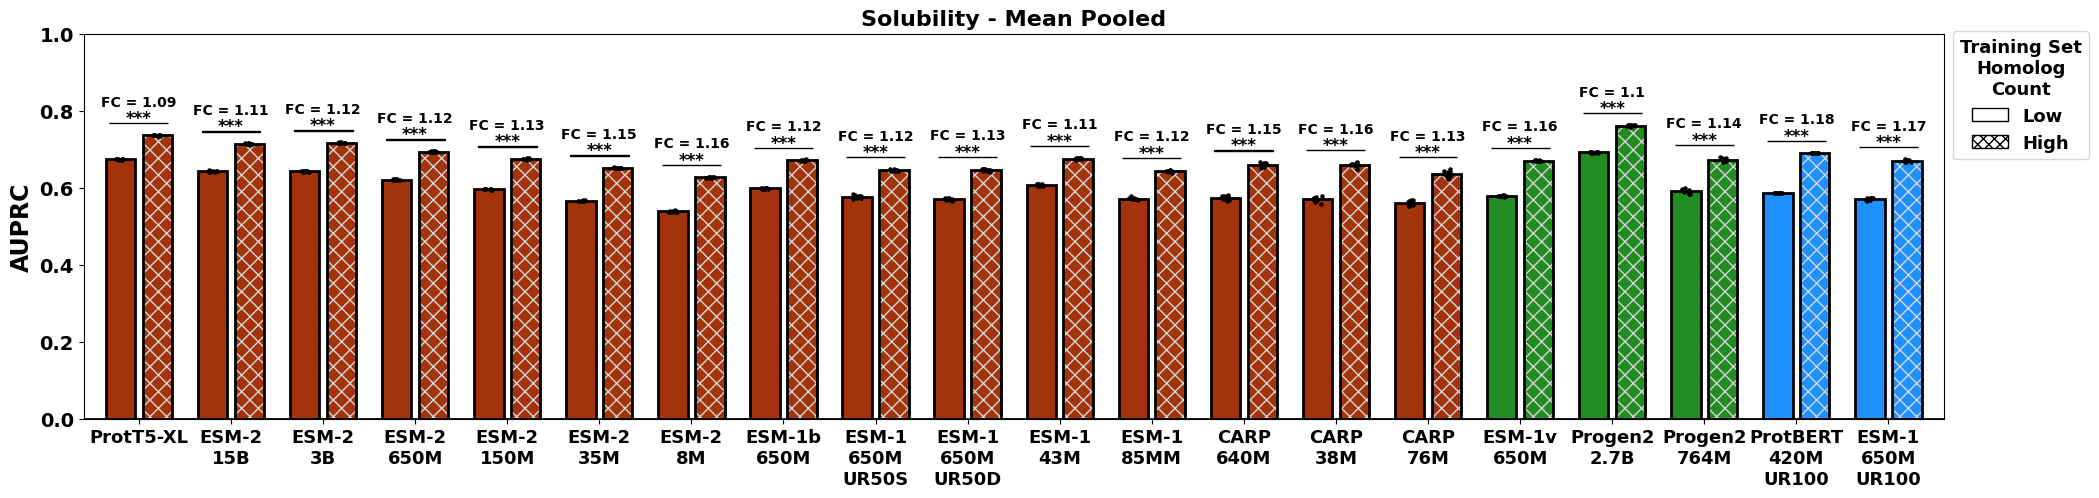

In [4]:

x = []
y = []


data = []

x_counter = 0


color_list = []


green_models = [
    "Progen2 (2.7B) UR90+BFD30",
    "Progen2 (764M) UR90+BFD30",
    "ESM-1v"
]
blue_models = [
    "ProtBERT",
    "ESM-1 (670M) UR100"
]


x_position_list = []
y_position_list = []

fc_list = []

stars_list = []

label_list = []

y_offset = 0.03

for index, row in data_E3a.iterrows():
    
    k = row["Model"]
    
    label_list.append(model_to_display_a[k])
    
   
    x1 = list(map(lambda x : float(x), row["Low Homolog Count Results"].split("|")))
    x2 = list(map(lambda x : float(x), row["High Homolog Count Results"].split("|")))
    
    st, p = scipy.stats.mannwhitneyu(x2, x1, alternative = "greater")
    stars_list.append(p_val_to_stars(p))
    
    
    
    m_1, ci_l_1, ci_h_1 = mean_confidence_interval(x1)
    
    x.append(x_counter)
    data.append(x1)
    y.append(m_1)
    
    x_counter += 1
    
    x_position_list.append(x_counter - 0.5)
    
    
    
    m_2, ci_l_2, ci_h_ = mean_confidence_interval(x2)
    
    y_position_list.append(max(np.max(x1), np.max(x2)) + y_offset)
    
    x.append(x_counter)
    data.append(x2)
    y.append(m_2)
    
    x_counter += 1
    x_counter += 0.5
    
    c = "#a2330b"
    if k in green_models:
        c = "forestgreen"
    elif k in blue_models:
        c = "dodgerblue"
        
    color_list.append(c)
    color_list.append(c)
    
    fc = m_2 / m_1
    
    fc_list.append(fc)
    
    

legend_handles = [
    mpatches.Patch(facecolor="white", edgecolor="black", label="Low", ),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch="xxx", label="High",)
]

    
fig, ax = plt.subplots(figsize = (1.2*len(label_list),5))


bars = ax.bar(
    x, 
    y,
    edgecolor = "black",
    color = color_list,
    linewidth = 2,
    hatch = ["", "xx"] * int((len(x) / 2))
)


# Flatten raw data
strip_x = []
strip_y = []

for xi, values in zip(x, data):
    strip_x.extend([xi] * len(values))
    strip_y.extend(values)

for xi, values in zip(x, data):
    jitter = np.random.uniform(-0.12, 0.12, len(values))

    ax.scatter(
        xi + jitter,
        values,
        color="black",
        s=5,
        zorder=10,
        marker = "o"
    )
    
for bar in bars:
    bar._hatch_color = to_rgba("#d6d6d6")  
    
for x_i, x_val in enumerate(x_position_list):
    y_val = y_position_list[x_i]
    rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")
    ax.add_patch(rect)
    
    stars = stars_list[x_i]
    
    stars_fs = 12 if stars != "ns" else 9
    
    stars_offset = 0.012 if stars == "ns" else 0
    
    
    fc_str = str(round(fc_list[x_i], 2))
    ax.text(x_val, y_val + 0.045, "FC = " + fc_str, fontweight = "bold", horizontalalignment = "center") 
    
    ax.text(x_val, y_val  + stars_offset, stars, fontsize = stars_fs, fontweight = "bold", horizontalalignment = "center") 
    
    
ax.set_xticks(x_position_list)
ax.set_xticklabels(label_list, fontweight = "bold", fontsize = 13)
ax.set_xlim(left = np.min(x_position_list) - 1.5, right = np.max(x_position_list) + 1.5)

ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(ax.get_yticklabels(), fontsize = 14, fontweight = "bold",)


ax.axhline(y = 0, color = "black", linewidth = 2)


ax.set_ylabel(f"AUPRC", fontsize = 17, fontweight="bold" )

leg = ax.legend(
    handles=legend_handles,
    title="Training Set\nHomolog\nCount",
    loc="center left",
    bbox_to_anchor=(1, 0.84), 
    fontsize = 13,
    alignment="center",
    
)

legend_handles = [
    mpatches.Patch(facecolor="white", edgecolor="black", label="Low", ),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch="xxx", label="High",)
]

leg.get_title().set_ha("center")
leg.get_title().set_fontweight("bold")
leg.get_title().set_fontsize(13)

for text in leg.get_texts():
    text.set_fontweight("bold")

ax.set_title("Solubility - Mean Pooled", fontweight = "bold", fontsize = 16)



/tmp/ipykernel_1805228/404517862.py:132: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")


Text(0.5, 1.0, 'Subcellular Localization - Mean Pooled')

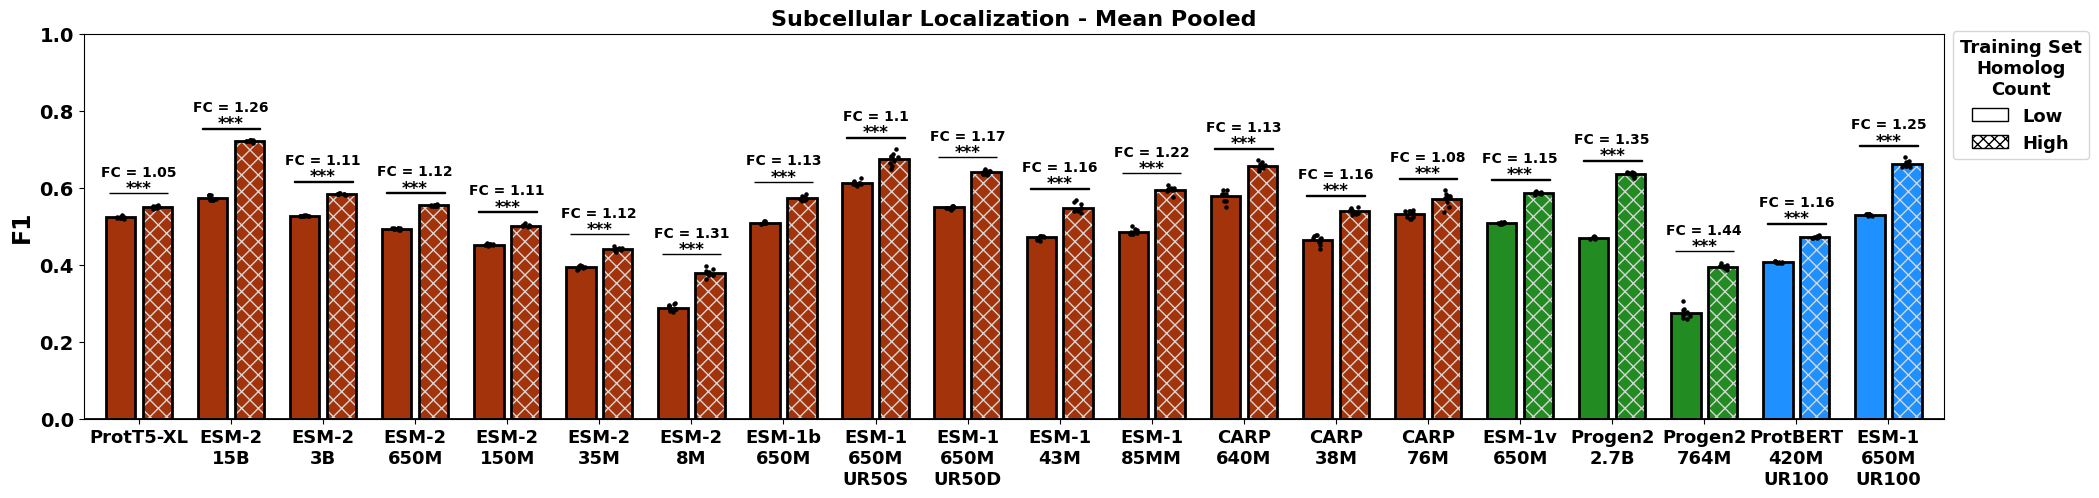

In [5]:

x = []
y = []


data = []

x_counter = 0


color_list = []


green_models = [
    "Progen2 (2.7B) UR90+BFD30",
    "Progen2 (764M) UR90+BFD30",
    "ESM-1v"
]
blue_models = [
    "ProtBERT",
    "ESM-1 (670M) UR100"
]


x_position_list = []
y_position_list = []

fc_list = []

stars_list = []

label_list = []

y_offset = 0.03

for index, row in data_E3b.iterrows():
    
    k = row["Model"]
    
    label_list.append(model_to_display_a[k])
    
   
    x1 = list(map(lambda x : float(x), row["Low Homolog Count Results"].split("|")))
    x2 = list(map(lambda x : float(x), row["High Homolog Count Results"].split("|")))
    
    st, p = scipy.stats.mannwhitneyu(x2, x1, alternative = "greater")
    stars_list.append(p_val_to_stars(p))
    
    
    
    m_1, ci_l_1, ci_h_1 = mean_confidence_interval(x1)
    
    x.append(x_counter)
    data.append(x1)
    y.append(m_1)
    
    x_counter += 1
    
    x_position_list.append(x_counter - 0.5)
    
    
    
    m_2, ci_l_2, ci_h_ = mean_confidence_interval(x2)
    
    y_position_list.append(max(np.max(x1), np.max(x2)) + y_offset)
    
    x.append(x_counter)
    data.append(x2)
    y.append(m_2)
    
    x_counter += 1
    x_counter += 0.5
    
    c = "#a2330b"
    if k in green_models:
        c = "forestgreen"
    elif k in blue_models:
        c = "dodgerblue"
        
    color_list.append(c)
    color_list.append(c)
    
    fc = m_2 / m_1
    
    fc_list.append(fc)
    
    

legend_handles = [
    mpatches.Patch(facecolor="white", edgecolor="black", label="Low", ),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch="xxx", label="High",)
]

    
fig, ax = plt.subplots(figsize = (1.2*len(label_list),5))


bars = ax.bar(
    x, 
    y,
    edgecolor = "black",
    color = color_list,
    linewidth = 2,
    hatch = ["", "xx"] * int((len(x) / 2))
)


# Flatten raw data
strip_x = []
strip_y = []

for xi, values in zip(x, data):
    strip_x.extend([xi] * len(values))
    strip_y.extend(values)

for xi, values in zip(x, data):
    jitter = np.random.uniform(-0.12, 0.12, len(values))

    ax.scatter(
        xi + jitter,
        values,
        color="black",
        s=5,
        zorder=10,
        marker = "o"
    )
    
for bar in bars:
    bar._hatch_color = to_rgba("#d6d6d6")  
    
for x_i, x_val in enumerate(x_position_list):
    y_val = y_position_list[x_i]
    rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")
    ax.add_patch(rect)
    
    stars = stars_list[x_i]
    
    stars_fs = 12 if stars != "ns" else 9
    
    stars_offset = 0.012 if stars == "ns" else 0
    
    
    fc_str = str(round(fc_list[x_i], 2))
    ax.text(x_val, y_val + 0.045, "FC = " + fc_str, fontweight = "bold", horizontalalignment = "center") 
    
    ax.text(x_val, y_val  + stars_offset, stars, fontsize = stars_fs, fontweight = "bold", horizontalalignment = "center") 
    
    
ax.set_xticks(x_position_list)
ax.set_xticklabels(label_list, fontweight = "bold", fontsize = 13)
ax.set_xlim(left = np.min(x_position_list) - 1.5, right = np.max(x_position_list) + 1.5)

ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(ax.get_yticklabels(), fontsize = 14, fontweight = "bold",)


ax.axhline(y = 0, color = "black", linewidth = 2)


ax.set_ylabel(f"F1", fontsize = 17, fontweight="bold" )

leg = ax.legend(
    handles=legend_handles,
    title="Training Set\nHomolog\nCount",
    loc="center left",
    bbox_to_anchor=(1, 0.84), 
    fontsize = 13,
    alignment="center",
    
)

legend_handles = [
    mpatches.Patch(facecolor="white", edgecolor="black", label="Low", ),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch="xxx", label="High",)
]

leg.get_title().set_ha("center")
leg.get_title().set_fontweight("bold")
leg.get_title().set_fontsize(13)

for text in leg.get_texts():
    text.set_fontweight("bold")

ax.set_title("Subcellular Localization - Mean Pooled", fontweight = "bold", fontsize = 16)



9.133589555477501e-05
9.133589555477501e-05
0.9999325785388228
9.133589555477501e-05
0.0011011099712485391
9.133589555477501e-05
9.133589555477501e-05
9.133589555477501e-05
9.082557304573249e-05
9.133589555477501e-05
9.133589555477501e-05
9.133589555477501e-05
0.00029141997158963715
9.133589555477501e-05
9.133589555477501e-05
0.9999325785388228
0.7636622032442064
9.133589555477501e-05
9.133589555477501e-05
9.133589555477501e-05


/tmp/ipykernel_1805228/1463888291.py:133: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")


Text(0.5, 1.0, 'PPI Affinity - Mean Pooled')

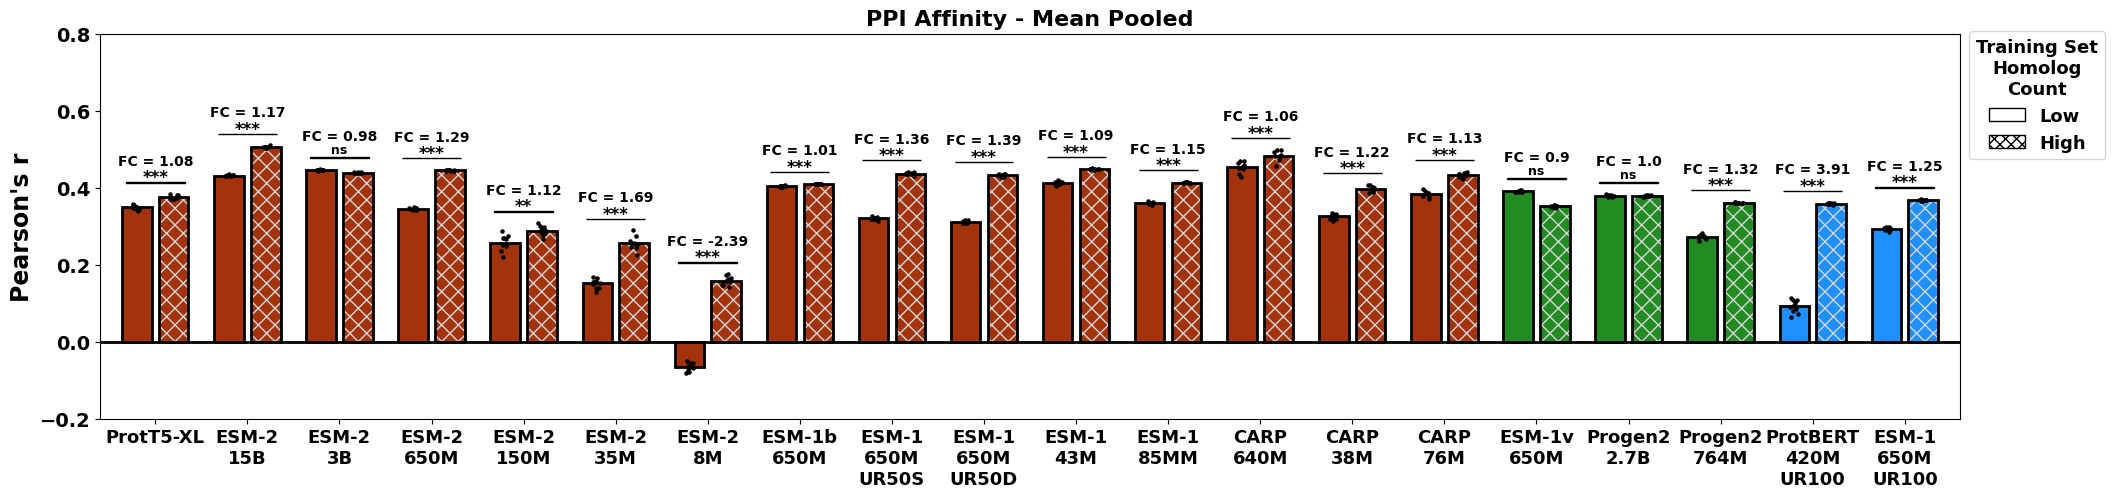

In [6]:

x = []
y = []


data = []

x_counter = 0


color_list = []


green_models = [
    "Progen2 (2.7B) UR90+BFD30",
    "Progen2 (764M) UR90+BFD30",
    "ESM-1v"
]
blue_models = [
    "ProtBERT",
    "ESM-1 (670M) UR100"
]


x_position_list = []
y_position_list = []

fc_list = []

stars_list = []

label_list = []

y_offset = 0.03

for index, row in data_E3c.iterrows():
    
    k = row["Model"]
    
    label_list.append(model_to_display_a[k])
    
   
    x1 = list(map(lambda x : float(x), row["Low Homolog Count Results"].split("|")))
    x2 = list(map(lambda x : float(x), row["High Homolog Count Results"].split("|")))
    
    st, p = scipy.stats.mannwhitneyu(x2, x1, alternative = "greater")
    print(p)
    stars_list.append(p_val_to_stars(p))
    
    
    
    m_1, ci_l_1, ci_h_1 = mean_confidence_interval(x1)
    
    x.append(x_counter)
    data.append(x1)
    y.append(m_1)
    
    x_counter += 1
    
    x_position_list.append(x_counter - 0.5)
    
    
    
    m_2, ci_l_2, ci_h_ = mean_confidence_interval(x2)
    
    y_position_list.append(max(np.max(x1), np.max(x2)) + y_offset)
    
    x.append(x_counter)
    data.append(x2)
    y.append(m_2)
    
    x_counter += 1
    x_counter += 0.5
    
    c = "#a2330b"
    if k in green_models:
        c = "forestgreen"
    elif k in blue_models:
        c = "dodgerblue"
        
    color_list.append(c)
    color_list.append(c)
    
    fc = m_2 / m_1
    
    fc_list.append(fc)
    
    

legend_handles = [
    mpatches.Patch(facecolor="white", edgecolor="black", label="Low", ),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch="xxx", label="High",)
]

    
fig, ax = plt.subplots(figsize = (1.2*len(label_list),5))


bars = ax.bar(
    x, 
    y,
    edgecolor = "black",
    color = color_list,
    linewidth = 2,
    hatch = ["", "xx"] * int((len(x) / 2))
)


# Flatten raw data
strip_x = []
strip_y = []

for xi, values in zip(x, data):
    strip_x.extend([xi] * len(values))
    strip_y.extend(values)

for xi, values in zip(x, data):
    jitter = np.random.uniform(-0.12, 0.12, len(values))

    ax.scatter(
        xi + jitter,
        values,
        color="black",
        s=5,
        zorder=10,
        marker = "o"
    )
    
for bar in bars:
    bar._hatch_color = to_rgba("#d6d6d6")  
    
for x_i, x_val in enumerate(x_position_list):
    y_val = y_position_list[x_i]
    rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")
    ax.add_patch(rect)
    
    stars = stars_list[x_i]
    
    stars_fs = 12 if stars != "ns" else 9
    
    stars_offset = 0.012 if stars == "ns" else 0
    
    
    fc_str = str(round(fc_list[x_i], 2))
    ax.text(x_val, y_val + 0.045, "FC = " + fc_str, fontweight = "bold", horizontalalignment = "center") 
    
    ax.text(x_val, y_val  + stars_offset, stars, fontsize = stars_fs, fontweight = "bold", horizontalalignment = "center") 
    
    
ax.set_xticks(x_position_list)
ax.set_xticklabels(label_list, fontweight = "bold", fontsize = 13)
ax.set_xlim(left = np.min(x_position_list) - 1.5, right = np.max(x_position_list) + 1.5)

ax.set_yticks([-0.2, 0, 0.2, 0.4, 0.6, 0.8])
ax.set_yticklabels(ax.get_yticklabels(), fontsize = 14, fontweight = "bold",)


ax.axhline(y = 0, color = "black", linewidth = 2)


ax.set_ylabel(f"Pearson's r", fontsize = 17, fontweight="bold" )

leg = ax.legend(
    handles=legend_handles,
    title="Training Set\nHomolog\nCount",
    loc="center left",
    bbox_to_anchor=(1, 0.84), 
    fontsize = 13,
    alignment="center",
    
)

legend_handles = [
    mpatches.Patch(facecolor="white", edgecolor="black", label="Low", ),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch="xxx", label="High",)
]

leg.get_title().set_ha("center")
leg.get_title().set_fontweight("bold")
leg.get_title().set_fontsize(13)

for text in leg.get_texts():
    text.set_fontweight("bold")

ax.set_title("PPI Affinity - Mean Pooled", fontweight = "bold", fontsize = 16)



/tmp/ipykernel_1805228/1297747009.py:139: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")


Text(0.5, 1.0, 'Solubility')

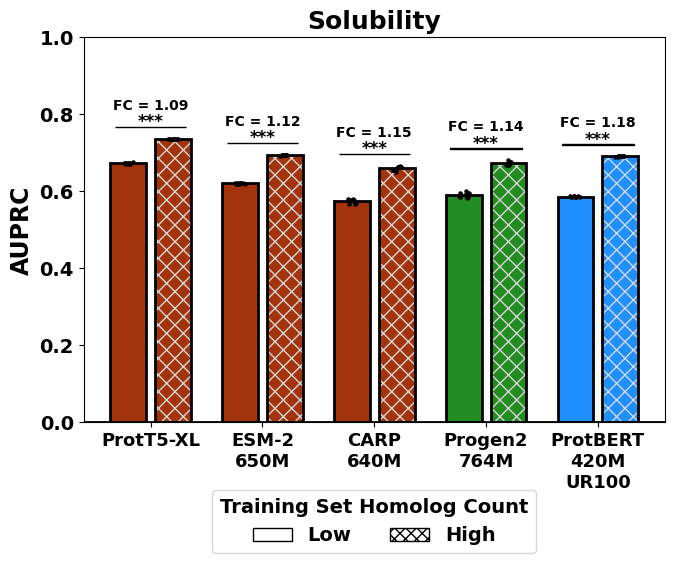

In [7]:
fig_3f_data = df.loc[
    (df["Task"] == "Solubility") & 
    (df["Pool Method"] == "mean_pooled") & 
    (df["Training Setup"] == "Downstream NN") & 
    (df["Model"].isin(["ProtT5-XL (3B) UR50", 'CARP (640M)', 'ESM-2 (650M)', 'Progen2 (764M) UR90+BFD30','ProtBERT' ]))
]


x = []
y = []


data = []

x_counter = 0


color_list = []


green_models = [
    "Progen2 (2.7B) UR90+BFD30",
    "Progen2 (764M) UR90+BFD30",
    "ESM-1v"
]
blue_models = [
    "ProtBERT",
    "ESM-1 (670M) UR100"
]


x_position_list = []
y_position_list = []

fc_list = []

stars_list = []

label_list = []

y_offset = 0.03

for index, row in fig_3f_data.iterrows():
    
    k = row["Model"]
    
    label_list.append(model_to_display_a[k])
    
   
    x1 = list(map(lambda x : float(x), row["Low Homolog Count Results"].split("|")))
    x2 = list(map(lambda x : float(x), row["High Homolog Count Results"].split("|")))
    
    st, p = scipy.stats.mannwhitneyu(x2, x1, alternative = "greater")
    stars_list.append(p_val_to_stars(p))
    
    
    m_1, ci_l_1, ci_h_1 = mean_confidence_interval(x1)
    
    x.append(x_counter)
    data.append(x1)
    y.append(m_1)
    
    x_counter += 1
    
    x_position_list.append(x_counter - 0.5)
    
    
    
    m_2, ci_l_2, ci_h_ = mean_confidence_interval(x2)
    
    y_position_list.append(max(np.max(x1), np.max(x2)) + y_offset)
    
    x.append(x_counter)
    data.append(x2)
    y.append(m_2)
    
    x_counter += 1
    x_counter += 0.5
    
    c = "#a2330b"
    if k in green_models:
        c = "forestgreen"
    elif k in blue_models:
        c = "dodgerblue"
        
    color_list.append(c)
    color_list.append(c)
    
    fc = m_2 / m_1
    
    fc_list.append(fc)
    
    

legend_handles = [
    mpatches.Patch(facecolor="white", edgecolor="black", label="Low", ),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch="xxx", label="High",)
]

    
fig, ax = plt.subplots(figsize = (1.5*len(label_list),5))


bars = ax.bar(
    x, 
    y,
    edgecolor = "black",
    color = color_list,
    linewidth = 2,
    hatch = ["", "xx"] * int((len(x) / 2))
)


# Flatten raw data
strip_x = []
strip_y = []

for xi, values in zip(x, data):
    strip_x.extend([xi] * len(values))
    strip_y.extend(values)

for xi, values in zip(x, data):
    jitter = np.random.uniform(-0.12, 0.12, len(values))

    ax.scatter(
        xi + jitter,
        values,
        color="black",
        s=5,
        zorder=10,
        marker = "o"
    )
    
for bar in bars:
    bar._hatch_color = to_rgba("#d6d6d6")  
    
for x_i, x_val in enumerate(x_position_list):
    y_val = y_position_list[x_i]
    rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")
    ax.add_patch(rect)
    
    stars = stars_list[x_i]
    
    stars_fs = 12 if stars != "ns" else 9
    
    stars_offset = 0.012 if stars == "ns" else 0
    
    
    fc_str = str(round(fc_list[x_i], 2))
    ax.text(x_val, y_val + 0.045, "FC = " + fc_str, fontweight = "bold", horizontalalignment = "center") 
    
    ax.text(x_val, y_val  + stars_offset, stars, fontsize = stars_fs, fontweight = "bold", horizontalalignment = "center") 
    
    
ax.set_xticks(x_position_list)
ax.set_xticklabels(label_list, fontweight = "bold", fontsize = 13)
ax.set_xlim(left = np.min(x_position_list) - 1.5, right = np.max(x_position_list) + 1.5)

ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(ax.get_yticklabels(), fontsize = 14, fontweight = "bold",)


ax.axhline(y = 0, color = "black", linewidth = 2)


ax.set_ylabel(f"AUPRC", fontsize = 17, fontweight="bold" )

leg = ax.legend(
    handles=legend_handles,
    title="Training Set Homolog Count",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=2,
    fontsize=14,
    alignment="center",
    frameon=True,
)

leg.get_title().set_ha("center")
leg.get_title().set_fontweight("bold")
leg.get_title().set_fontsize(14)

for text in leg.get_texts():
    text.set_fontweight("bold")


ax.set_title("Solubility", fontweight = "bold", fontsize = 18)





/tmp/ipykernel_1805228/577673992.py:139: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")


Text(0.5, 1.0, 'PPI Affinity')

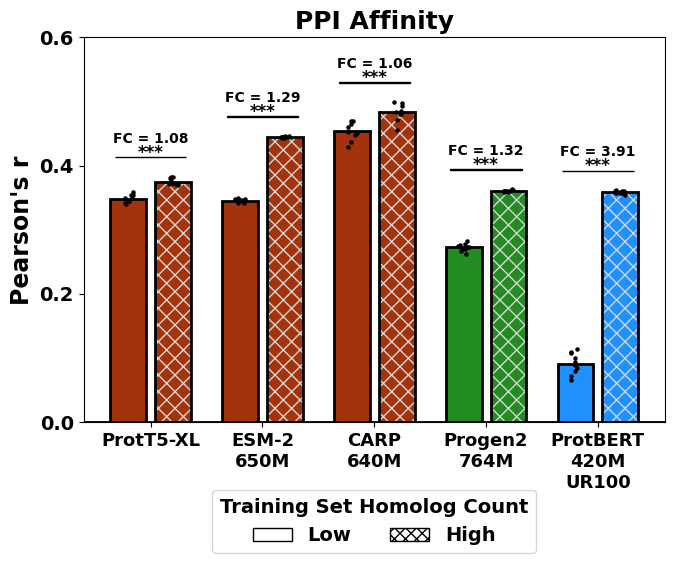

In [8]:
fig_3f_data = df.loc[
    (df["Task"] == "PPI Affinity") & 
    (df["Pool Method"] == "mean_pooled") & 
    (df["Training Setup"] == "Downstream NN") & 
    (df["Model"].isin(["ProtT5-XL (3B) UR50", 'CARP (640M)', 'ESM-2 (650M)', 'Progen2 (764M) UR90+BFD30','ProtBERT' ]))
]


x = []
y = []


data = []

x_counter = 0


color_list = []


green_models = [
    "Progen2 (2.7B) UR90+BFD30",
    "Progen2 (764M) UR90+BFD30",
    "ESM-1v"
]
blue_models = [
    "ProtBERT",
    "ESM-1 (670M) UR100"
]


x_position_list = []
y_position_list = []

fc_list = []

stars_list = []

label_list = []

y_offset = 0.03

for index, row in fig_3f_data.iterrows():
    
    k = row["Model"]
    
    label_list.append(model_to_display_a[k])
    
   
    x1 = list(map(lambda x : float(x), row["Low Homolog Count Results"].split("|")))
    x2 = list(map(lambda x : float(x), row["High Homolog Count Results"].split("|")))
    
    st, p = scipy.stats.mannwhitneyu(x2, x1, alternative = "greater")
    stars_list.append(p_val_to_stars(p))
    
    
    m_1, ci_l_1, ci_h_1 = mean_confidence_interval(x1)
    
    x.append(x_counter)
    data.append(x1)
    y.append(m_1)
    
    x_counter += 1
    
    x_position_list.append(x_counter - 0.5)
    
    
    
    m_2, ci_l_2, ci_h_ = mean_confidence_interval(x2)
    
    y_position_list.append(max(np.max(x1), np.max(x2)) + y_offset)
    
    x.append(x_counter)
    data.append(x2)
    y.append(m_2)
    
    x_counter += 1
    x_counter += 0.5
    
    c = "#a2330b"
    if k in green_models:
        c = "forestgreen"
    elif k in blue_models:
        c = "dodgerblue"
        
    color_list.append(c)
    color_list.append(c)
    
    fc = m_2 / m_1
    
    fc_list.append(fc)
    
    

legend_handles = [
    mpatches.Patch(facecolor="white", edgecolor="black", label="Low", ),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch="xxx", label="High",)
]

    
fig, ax = plt.subplots(figsize = (1.5*len(label_list),5))


bars = ax.bar(
    x, 
    y,
    edgecolor = "black",
    color = color_list,
    linewidth = 2,
    hatch = ["", "xx"] * int((len(x) / 2))
)


# Flatten raw data
strip_x = []
strip_y = []

for xi, values in zip(x, data):
    strip_x.extend([xi] * len(values))
    strip_y.extend(values)

for xi, values in zip(x, data):
    jitter = np.random.uniform(-0.12, 0.12, len(values))

    ax.scatter(
        xi + jitter,
        values,
        color="black",
        s=5,
        zorder=10,
        marker = "o"
    )
    
for bar in bars:
    bar._hatch_color = to_rgba("#d6d6d6")  
    
for x_i, x_val in enumerate(x_position_list):
    y_val = y_position_list[x_i]
    rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")
    ax.add_patch(rect)
    
    stars = stars_list[x_i]
    
    stars_fs = 12 if stars != "ns" else 9
    
    stars_offset = 0.012 if stars == "ns" else 0
    
    
    fc_str = str(round(fc_list[x_i], 2))
    ax.text(x_val, y_val + 0.023, "FC = " + fc_str, fontweight = "bold", horizontalalignment = "center") 
    
    ax.text(x_val, y_val  + stars_offset, stars, fontsize = stars_fs, fontweight = "bold", horizontalalignment = "center") 
    
    
ax.set_xticks(x_position_list)
ax.set_xticklabels(label_list, fontweight = "bold", fontsize = 13)
ax.set_xlim(left = np.min(x_position_list) - 1.5, right = np.max(x_position_list) + 1.5)

ax.set_yticks([0, 0.2, 0.4, 0.6])
ax.set_yticklabels(ax.get_yticklabels(), fontsize = 14, fontweight = "bold",)


ax.axhline(y = 0, color = "black", linewidth = 2)


ax.set_ylabel(f"Pearson's r", fontsize = 17, fontweight="bold" )

    
leg = ax.legend(
    handles=legend_handles,
    title="Training Set Homolog Count",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=2,
    fontsize=14,
    alignment="center",
    frameon=True,
)

leg.get_title().set_ha("center")
leg.get_title().set_fontweight("bold")
leg.get_title().set_fontsize(14)

for text in leg.get_texts():
    text.set_fontweight("bold")

ax.set_title("PPI Affinity", fontweight = "bold", fontsize = 18)





/tmp/ipykernel_1805228/2357035008.py:138: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")


Text(0.5, 1.0, 'Solubility - CLS Pooled')

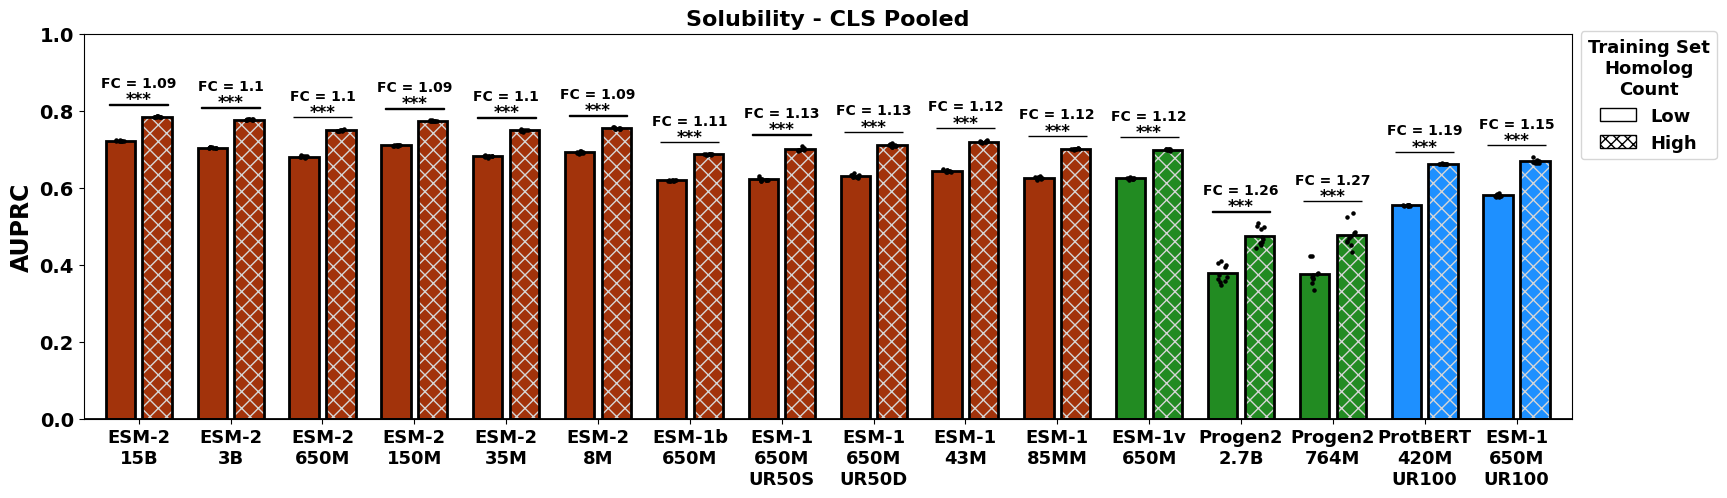

In [9]:

x = []
y = []


data = []

x_counter = 0


color_list = []


green_models = [
    "Progen2 (2.7B) UR90+BFD30",
    "Progen2 (764M) UR90+BFD30",
    "ESM-1v"
]
blue_models = [
    "ProtBERT",
    "ESM-1 (670M) UR100"
]


x_position_list = []
y_position_list = []

fc_list = []

stars_list = []

label_list = []

y_offset = 0.03

data_S2a = df.loc[
    (df["Task"] == "Solubility") & 
    (df["Pool Method"] == "CLS_pooled") & 
    (df["Training Setup"] == "Downstream NN") 
]

for index, row in data_S2a.iterrows():
    
    k = row["Model"]
    
    label_list.append(model_to_display_a[k])
    
   
    x1 = list(map(lambda x : float(x), row["Low Homolog Count Results"].split("|")))
    x2 = list(map(lambda x : float(x), row["High Homolog Count Results"].split("|")))
    
    st, p = scipy.stats.mannwhitneyu(x2, x1, alternative = "greater")
    stars_list.append(p_val_to_stars(p))
    
    
    
    m_1, ci_l_1, ci_h_1 = mean_confidence_interval(x1)
    
    x.append(x_counter)
    data.append(x1)
    y.append(m_1)
    
    x_counter += 1
    
    x_position_list.append(x_counter - 0.5)
    
    
    
    m_2, ci_l_2, ci_h_ = mean_confidence_interval(x2)
    
    y_position_list.append(max(np.max(x1), np.max(x2)) + y_offset)
    
    x.append(x_counter)
    data.append(x2)
    y.append(m_2)
    
    x_counter += 1
    x_counter += 0.5
    
    c = "#a2330b"
    if k in green_models:
        c = "forestgreen"
    elif k in blue_models:
        c = "dodgerblue"
        
    color_list.append(c)
    color_list.append(c)
    
    fc = m_2 / m_1
    
    fc_list.append(fc)
    
    

legend_handles = [
    mpatches.Patch(facecolor="white", edgecolor="black", label="Low", ),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch="xxx", label="High",)
]

    
fig, ax = plt.subplots(figsize = (1.2*len(label_list),5))


bars = ax.bar(
    x, 
    y,
    edgecolor = "black",
    color = color_list,
    linewidth = 2,
    hatch = ["", "xx"] * int((len(x) / 2))
)


# Flatten raw data
strip_x = []
strip_y = []

for xi, values in zip(x, data):
    strip_x.extend([xi] * len(values))
    strip_y.extend(values)

for xi, values in zip(x, data):
    jitter = np.random.uniform(-0.12, 0.12, len(values))

    ax.scatter(
        xi + jitter,
        values,
        color="black",
        s=5,
        zorder=10,
        marker = "o"
    )
    
for bar in bars:
    bar._hatch_color = to_rgba("#d6d6d6")  
    
for x_i, x_val in enumerate(x_position_list):
    y_val = y_position_list[x_i]
    rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")
    ax.add_patch(rect)
    
    stars = stars_list[x_i]
    
    stars_fs = 12 if stars != "ns" else 9
    
    stars_offset = 0.012 if stars == "ns" else 0
    
    
    fc_str = str(round(fc_list[x_i], 2))
    ax.text(x_val, y_val + 0.045, "FC = " + fc_str, fontweight = "bold", horizontalalignment = "center") 
    
    ax.text(x_val, y_val  + stars_offset, stars, fontsize = stars_fs, fontweight = "bold", horizontalalignment = "center") 
    
    
ax.set_xticks(x_position_list)
ax.set_xticklabels(label_list, fontweight = "bold", fontsize = 13)
ax.set_xlim(left = np.min(x_position_list) - 1.5, right = np.max(x_position_list) + 1.5)

ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(ax.get_yticklabels(), fontsize = 14, fontweight = "bold",)


ax.axhline(y = 0, color = "black", linewidth = 2)


ax.set_ylabel(f"AUPRC", fontsize = 17, fontweight="bold" )

leg = ax.legend(
    handles=legend_handles,
    title="Training Set\nHomolog\nCount",
    loc="center left",
    bbox_to_anchor=(1, 0.84), 
    fontsize = 13,
    alignment="center",
    
)

legend_handles = [
    mpatches.Patch(facecolor="white", edgecolor="black", label="Low", ),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch="xxx", label="High",)
]

leg.get_title().set_ha("center")
leg.get_title().set_fontweight("bold")
leg.get_title().set_fontsize(13)

for text in leg.get_texts():
    text.set_fontweight("bold")

ax.set_title("Solubility - CLS Pooled", fontweight = "bold", fontsize = 16)



/tmp/ipykernel_1805228/856018955.py:138: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")


Text(0.5, 1.0, 'Subcellular Localization - CLS Pooled')

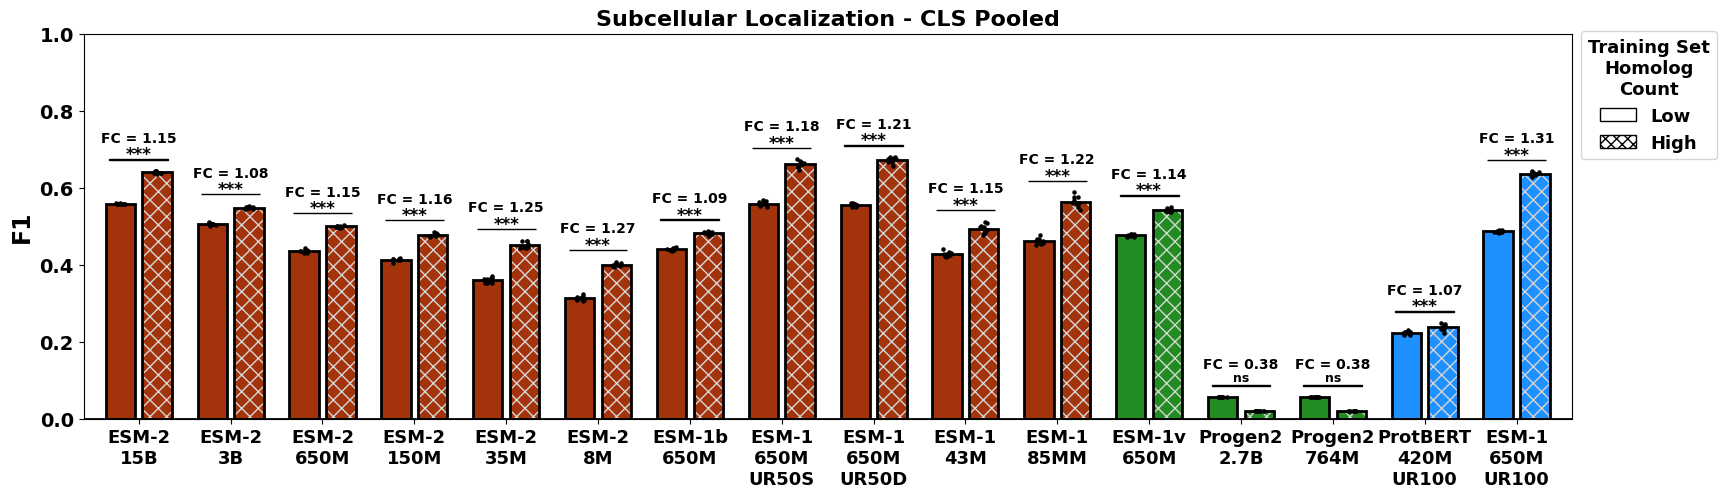

In [10]:

x = []
y = []


data = []

x_counter = 0


color_list = []


green_models = [
    "Progen2 (2.7B) UR90+BFD30",
    "Progen2 (764M) UR90+BFD30",
    "ESM-1v"
]
blue_models = [
    "ProtBERT",
    "ESM-1 (670M) UR100"
]


x_position_list = []
y_position_list = []

fc_list = []

stars_list = []

label_list = []

y_offset = 0.03

data_S2b = df.loc[
    (df["Task"] == "Subcellular Localization") & 
    (df["Pool Method"] == "CLS_pooled") & 
    (df["Training Setup"] == "Downstream NN") 
]

for index, row in data_S2b.iterrows():
    
    k = row["Model"]
    
    label_list.append(model_to_display_a[k])
    
   
    x1 = list(map(lambda x : float(x), row["Low Homolog Count Results"].split("|")))
    x2 = list(map(lambda x : float(x), row["High Homolog Count Results"].split("|")))
    
    st, p = scipy.stats.mannwhitneyu(x2, x1, alternative = "greater")
    stars_list.append(p_val_to_stars(p))
    
    
    
    m_1, ci_l_1, ci_h_1 = mean_confidence_interval(x1)
    
    x.append(x_counter)
    data.append(x1)
    y.append(m_1)
    
    x_counter += 1
    
    x_position_list.append(x_counter - 0.5)
    
    
    
    m_2, ci_l_2, ci_h_ = mean_confidence_interval(x2)
    
    y_position_list.append(max(np.max(x1), np.max(x2)) + y_offset)
    
    x.append(x_counter)
    data.append(x2)
    y.append(m_2)
    
    x_counter += 1
    x_counter += 0.5
    
    c = "#a2330b"
    if k in green_models:
        c = "forestgreen"
    elif k in blue_models:
        c = "dodgerblue"
        
    color_list.append(c)
    color_list.append(c)
    
    fc = m_2 / m_1
    
    fc_list.append(fc)
    
    

legend_handles = [
    mpatches.Patch(facecolor="white", edgecolor="black", label="Low", ),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch="xxx", label="High",)
]

    
fig, ax = plt.subplots(figsize = (1.2*len(label_list),5))


bars = ax.bar(
    x, 
    y,
    edgecolor = "black",
    color = color_list,
    linewidth = 2,
    hatch = ["", "xx"] * int((len(x) / 2))
)


# Flatten raw data
strip_x = []
strip_y = []

for xi, values in zip(x, data):
    strip_x.extend([xi] * len(values))
    strip_y.extend(values)

for xi, values in zip(x, data):
    jitter = np.random.uniform(-0.12, 0.12, len(values))

    ax.scatter(
        xi + jitter,
        values,
        color="black",
        s=5,
        zorder=10,
        marker = "o"
    )
    
for bar in bars:
    bar._hatch_color = to_rgba("#d6d6d6")  
    
for x_i, x_val in enumerate(x_position_list):
    y_val = y_position_list[x_i]
    rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")
    ax.add_patch(rect)
    
    stars = stars_list[x_i]
    
    stars_fs = 12 if stars != "ns" else 9
    
    stars_offset = 0.012 if stars == "ns" else 0
    
    
    fc_str = str(round(fc_list[x_i], 2))
    ax.text(x_val, y_val + 0.045, "FC = " + fc_str, fontweight = "bold", horizontalalignment = "center") 
    
    ax.text(x_val, y_val  + stars_offset, stars, fontsize = stars_fs, fontweight = "bold", horizontalalignment = "center") 
    
    
ax.set_xticks(x_position_list)
ax.set_xticklabels(label_list, fontweight = "bold", fontsize = 13)
ax.set_xlim(left = np.min(x_position_list) - 1.5, right = np.max(x_position_list) + 1.5)

ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(ax.get_yticklabels(), fontsize = 14, fontweight = "bold",)


ax.axhline(y = 0, color = "black", linewidth = 2)


ax.set_ylabel(f"F1", fontsize = 17, fontweight="bold" )

leg = ax.legend(
    handles=legend_handles,
    title="Training Set\nHomolog\nCount",
    loc="center left",
    bbox_to_anchor=(1, 0.84), 
    fontsize = 13,
    alignment="center",
    
)

legend_handles = [
    mpatches.Patch(facecolor="white", edgecolor="black", label="Low", ),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch="xxx", label="High",)
]

leg.get_title().set_ha("center")
leg.get_title().set_fontweight("bold")
leg.get_title().set_fontsize(13)

for text in leg.get_texts():
    text.set_fontweight("bold")

ax.set_title("Subcellular Localization - CLS Pooled", fontweight = "bold", fontsize = 16)



/tmp/ipykernel_1805228/3519929844.py:142: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")


Text(0.5, 1.0, 'PPI Affinity - CLS Pooled')

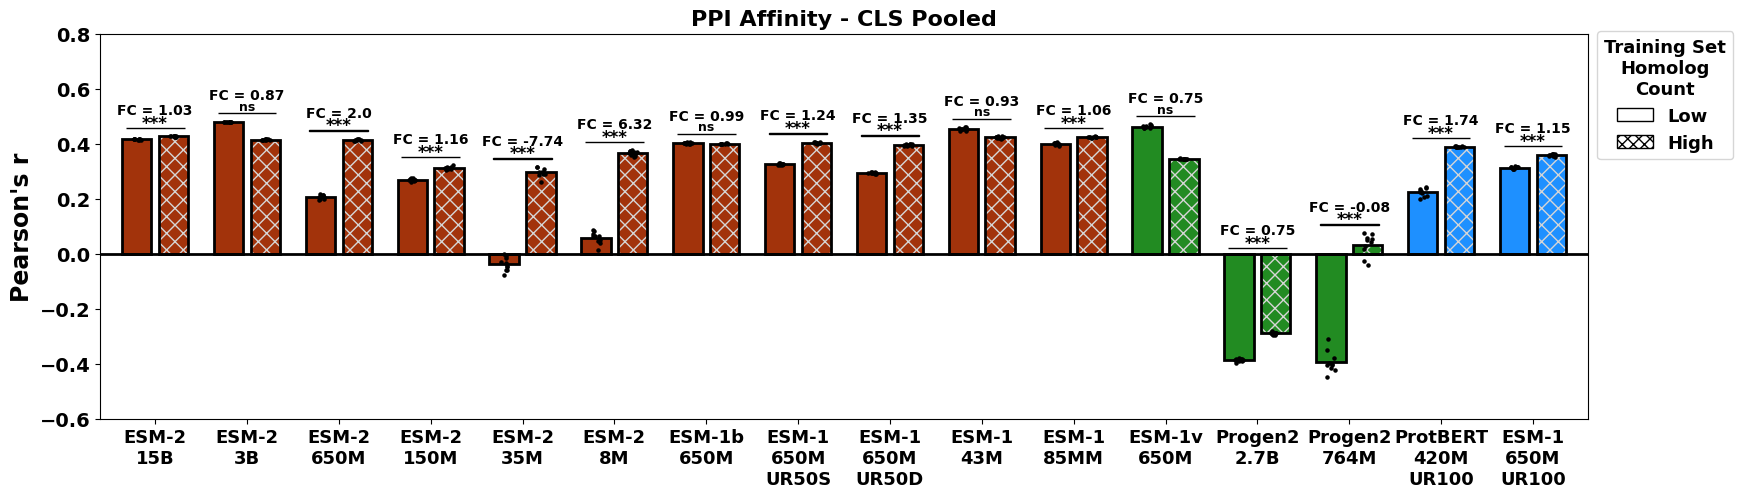

In [11]:

x = []
y = []


data = []

x_counter = 0


color_list = []


green_models = [
    "Progen2 (2.7B) UR90+BFD30",
    "Progen2 (764M) UR90+BFD30",
    "ESM-1v"
]
blue_models = [
    "ProtBERT",
    "ESM-1 (670M) UR100"
]


x_position_list = []
y_position_list = []

fc_list = []

stars_list = []

label_list = []

y_offset = 0.03

data_S2b = df.loc[
    (df["Task"] == "PPI Affinity") & 
    (df["Pool Method"] == "CLS_pooled") & 
    (df["Training Setup"] == "Downstream NN") 
]

for index, row in data_S2b.iterrows():
    
    k = row["Model"]
    
    label_list.append(model_to_display_a[k])
    
   
    x1 = list(map(lambda x : float(x), row["Low Homolog Count Results"].split("|")))
    x2 = list(map(lambda x : float(x), row["High Homolog Count Results"].split("|")))
    
    st, p = scipy.stats.mannwhitneyu(x2, x1, alternative = "greater")
    stars_list.append(p_val_to_stars(p))
    
    
    
    m_1, ci_l_1, ci_h_1 = mean_confidence_interval(x1)
    
    x.append(x_counter)
    data.append(x1)
    y.append(m_1)
    
    x_counter += 1
    
    x_position_list.append(x_counter - 0.5)
    
    
    
    m_2, ci_l_2, ci_h_ = mean_confidence_interval(x2)
    
    y_pos_loc = max(np.max(x1), np.max(x2)) + y_offset
    
    if y_pos_loc < 0:
        y_pos_loc = 0.02
    y_position_list.append(y_pos_loc)
    
    x.append(x_counter)
    data.append(x2)
    y.append(m_2)
    
    x_counter += 1
    x_counter += 0.5
    
    c = "#a2330b"
    if k in green_models:
        c = "forestgreen"
    elif k in blue_models:
        c = "dodgerblue"
        
    color_list.append(c)
    color_list.append(c)
    
    fc = m_2 / m_1
    
    fc_list.append(fc)
    
    

legend_handles = [
    mpatches.Patch(facecolor="white", edgecolor="black", label="Low", ),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch="xxx", label="High",)
]

    
fig, ax = plt.subplots(figsize = (1.2*len(label_list),5))


bars = ax.bar(
    x, 
    y,
    edgecolor = "black",
    color = color_list,
    linewidth = 2,
    hatch = ["", "xx"] * int((len(x) / 2))
)


# Flatten raw data
strip_x = []
strip_y = []

for xi, values in zip(x, data):
    strip_x.extend([xi] * len(values))
    strip_y.extend(values)

for xi, values in zip(x, data):
    jitter = np.random.uniform(-0.12, 0.12, len(values))

    ax.scatter(
        xi + jitter,
        values,
        color="black",
        s=5,
        zorder=10,
        marker = "o"
    )
    
for bar in bars:
    bar._hatch_color = to_rgba("#d6d6d6")  
    
for x_i, x_val in enumerate(x_position_list):
    y_val = y_position_list[x_i]
    rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")
    ax.add_patch(rect)
    
    stars = stars_list[x_i]
    
    stars_fs = 12 if stars != "ns" else 9
    
    stars_offset = 0.012 if stars == "ns" else 0
    
    
    fc_str = str(round(fc_list[x_i], 2))
    ax.text(x_val, y_val + 0.05, "FC = " + fc_str, fontweight = "bold", horizontalalignment = "center") 
    
    ax.text(x_val, y_val  + stars_offset, stars, fontsize = stars_fs, fontweight = "bold", horizontalalignment = "center") 
    
    
ax.set_xticks(x_position_list)
ax.set_xticklabels(label_list, fontweight = "bold", fontsize = 13)
ax.set_xlim(left = np.min(x_position_list) - 1.5, right = np.max(x_position_list) + 1.5)

ax.set_yticks([-0.6,-0.4, -0.2, 0, 0.2, 0.4, 0.6, 0.8 ])
ax.set_yticklabels(ax.get_yticklabels(), fontsize = 14, fontweight = "bold",)


ax.axhline(y = 0, color = "black", linewidth = 2)


ax.set_ylabel(f"Pearson's r", fontsize = 17, fontweight="bold" )

leg = ax.legend(
    handles=legend_handles,
    title="Training Set\nHomolog\nCount",
    loc="center left",
    bbox_to_anchor=(1, 0.84), 
    fontsize = 13,
    alignment="center",
    
)

legend_handles = [
    mpatches.Patch(facecolor="white", edgecolor="black", label="Low", ),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch="xxx", label="High",)
]

leg.get_title().set_ha("center")
leg.get_title().set_fontweight("bold")
leg.get_title().set_fontsize(13)

for text in leg.get_texts():
    text.set_fontweight("bold")

ax.set_title("PPI Affinity - CLS Pooled", fontweight = "bold", fontsize = 16)



/tmp/ipykernel_1805228/667866481.py:139: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")


Text(0.5, 1.0, 'Solubility')

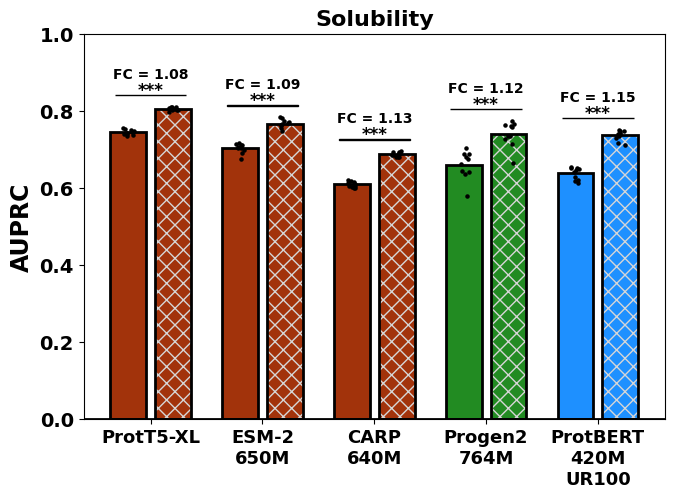

In [12]:
fig_E3d_a_data =  df.loc[
    (df["Task"] == "Solubility") & 
    (df["Pool Method"] == "mean_pooled") & 
    (df["Training Setup"] == "Fine Tuned") 
]



x = []
y = []


data = []

x_counter = 0


color_list = []


green_models = [
    "Progen2 (2.7B) UR90+BFD30",
    "Progen2 (764M) UR90+BFD30",
    "ESM-1v"
]
blue_models = [
    "ProtBERT",
    "ESM-1 (670M) UR100"
]


x_position_list = []
y_position_list = []

fc_list = []

stars_list = []

label_list = []

y_offset = 0.03

for index, row in fig_E3d_a_data.iterrows():
    
    k = row["Model"]
    
    label_list.append(model_to_display_a[k])
    
   
    x1 = list(map(lambda x : float(x), row["Low Homolog Count Results"].split("|")))
    x2 = list(map(lambda x : float(x), row["High Homolog Count Results"].split("|")))
    
    st, p = scipy.stats.mannwhitneyu(x2, x1, alternative = "greater")
    stars_list.append(p_val_to_stars(p))
    
    
    m_1, ci_l_1, ci_h_1 = mean_confidence_interval(x1)
    
    x.append(x_counter)
    data.append(x1)
    y.append(m_1)
    
    x_counter += 1
    
    x_position_list.append(x_counter - 0.5)
    
    
    
    m_2, ci_l_2, ci_h_ = mean_confidence_interval(x2)
    
    y_position_list.append(max(np.max(x1), np.max(x2)) + y_offset)
    
    x.append(x_counter)
    data.append(x2)
    y.append(m_2)
    
    x_counter += 1
    x_counter += 0.5
    
    c = "#a2330b"
    if k in green_models:
        c = "forestgreen"
    elif k in blue_models:
        c = "dodgerblue"
        
    color_list.append(c)
    color_list.append(c)
    
    fc = m_2 / m_1
    
    fc_list.append(fc)
    
    

legend_handles = [
    mpatches.Patch(facecolor="white", edgecolor="black", label="Low", ),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch="xxx", label="High",)
]

    
fig, ax = plt.subplots(figsize = (1.5*len(label_list),5))


bars = ax.bar(
    x, 
    y,
    edgecolor = "black",
    color = color_list,
    linewidth = 2,
    hatch = ["", "xx"] * int((len(x) / 2))
)


# Flatten raw data
strip_x = []
strip_y = []

for xi, values in zip(x, data):
    strip_x.extend([xi] * len(values))
    strip_y.extend(values)

for xi, values in zip(x, data):
    jitter = np.random.uniform(-0.12, 0.12, len(values))

    ax.scatter(
        xi + jitter,
        values,
        color="black",
        s=5,
        zorder=10,
        marker = "o"
    )
    
for bar in bars:
    bar._hatch_color = to_rgba("#d6d6d6")  
    
for x_i, x_val in enumerate(x_position_list):
    y_val = y_position_list[x_i]
    rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")
    ax.add_patch(rect)
    
    stars = stars_list[x_i]
    
    stars_fs = 12 if stars != "ns" else 9
    
    stars_offset = 0.012 if stars == "ns" else 0
    
    
    fc_str = str(round(fc_list[x_i], 2))
    ax.text(x_val, y_val + 0.045, "FC = " + fc_str, fontweight = "bold", horizontalalignment = "center") 
    
    ax.text(x_val, y_val  + stars_offset, stars, fontsize = stars_fs, fontweight = "bold", horizontalalignment = "center") 
    
    
ax.set_xticks(x_position_list)
ax.set_xticklabels(label_list, fontweight = "bold", fontsize = 13)
ax.set_xlim(left = np.min(x_position_list) - 1.5, right = np.max(x_position_list) + 1.5)

ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(ax.get_yticklabels(), fontsize = 14, fontweight = "bold",)


ax.axhline(y = 0, color = "black", linewidth = 2)


ax.set_ylabel(f"AUPRC", fontsize = 17, fontweight="bold" )


ax.set_title("Solubility", fontweight = "bold", fontsize = 16)






/tmp/ipykernel_1805228/1856064992.py:138: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")


Text(0.5, 1.0, 'Subcellular Localization')

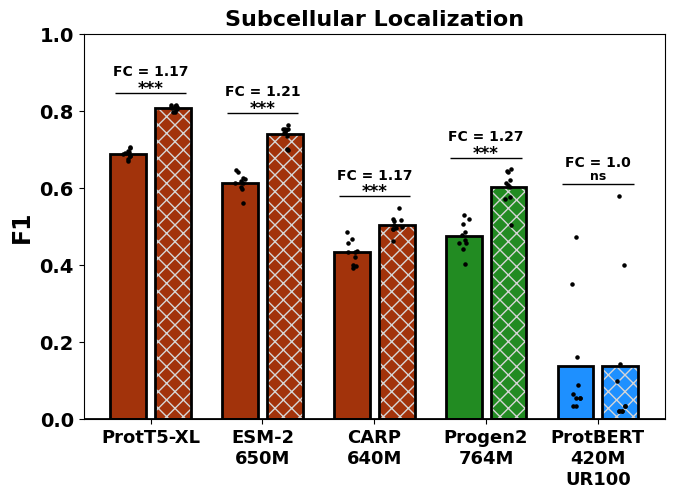

In [13]:
fig_E3d_b_data =  df.loc[
    (df["Task"] == "Subcellular Localization") & 
    (df["Pool Method"] == "mean_pooled") & 
    (df["Training Setup"] == "Fine Tuned") 
]


x = []
y = []


data = []

x_counter = 0


color_list = []


green_models = [
    "Progen2 (2.7B) UR90+BFD30",
    "Progen2 (764M) UR90+BFD30",
    "ESM-1v"
]
blue_models = [
    "ProtBERT",
    "ESM-1 (670M) UR100"
]


x_position_list = []
y_position_list = []

fc_list = []

stars_list = []

label_list = []

y_offset = 0.03

for index, row in fig_E3d_b_data.iterrows():
    
    k = row["Model"]
    
    label_list.append(model_to_display_a[k])
    
   
    x1 = list(map(lambda x : float(x), row["Low Homolog Count Results"].split("|")))
    x2 = list(map(lambda x : float(x), row["High Homolog Count Results"].split("|")))
    
    st, p = scipy.stats.mannwhitneyu(x2, x1, alternative = "greater")
    stars_list.append(p_val_to_stars(p))
    
    
    m_1, ci_l_1, ci_h_1 = mean_confidence_interval(x1)
    
    x.append(x_counter)
    data.append(x1)
    y.append(m_1)
    
    x_counter += 1
    
    x_position_list.append(x_counter - 0.5)
    
    
    
    m_2, ci_l_2, ci_h_ = mean_confidence_interval(x2)
    
    y_position_list.append(max(np.max(x1), np.max(x2)) + y_offset)
    
    x.append(x_counter)
    data.append(x2)
    y.append(m_2)
    
    x_counter += 1
    x_counter += 0.5
    
    c = "#a2330b"
    if k in green_models:
        c = "forestgreen"
    elif k in blue_models:
        c = "dodgerblue"
        
    color_list.append(c)
    color_list.append(c)
    
    fc = m_2 / m_1
    
    fc_list.append(fc)
    
    

legend_handles = [
    mpatches.Patch(facecolor="white", edgecolor="black", label="Low", ),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch="xxx", label="High",)
]

    
fig, ax = plt.subplots(figsize = (1.5*len(label_list),5))


bars = ax.bar(
    x, 
    y,
    edgecolor = "black",
    color = color_list,
    linewidth = 2,
    hatch = ["", "xx"] * int((len(x) / 2))
)


# Flatten raw data
strip_x = []
strip_y = []

for xi, values in zip(x, data):
    strip_x.extend([xi] * len(values))
    strip_y.extend(values)

for xi, values in zip(x, data):
    jitter = np.random.uniform(-0.12, 0.12, len(values))

    ax.scatter(
        xi + jitter,
        values,
        color="black",
        s=5,
        zorder=10,
        marker = "o"
    )
    
for bar in bars:
    bar._hatch_color = to_rgba("#d6d6d6")  
    
for x_i, x_val in enumerate(x_position_list):
    y_val = y_position_list[x_i]
    rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")
    ax.add_patch(rect)
    
    stars = stars_list[x_i]
    
    stars_fs = 12 if stars != "ns" else 9
    
    stars_offset = 0.012 if stars == "ns" else 0
    
    
    fc_str = str(round(fc_list[x_i], 2))
    ax.text(x_val, y_val + 0.045, "FC = " + fc_str, fontweight = "bold", horizontalalignment = "center") 
    
    ax.text(x_val, y_val  + stars_offset, stars, fontsize = stars_fs, fontweight = "bold", horizontalalignment = "center") 
    
    
ax.set_xticks(x_position_list)
ax.set_xticklabels(label_list, fontweight = "bold", fontsize = 13)
ax.set_xlim(left = np.min(x_position_list) - 1.5, right = np.max(x_position_list) + 1.5)

ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(ax.get_yticklabels(), fontsize = 14, fontweight = "bold",)


ax.axhline(y = 0, color = "black", linewidth = 2)


ax.set_ylabel(f"F1", fontsize = 17, fontweight="bold" )



ax.set_title("Subcellular Localization", fontweight = "bold", fontsize = 16)







/tmp/ipykernel_1805228/705731484.py:139: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")


Text(0.5, 1.0, 'PPI Affinity')

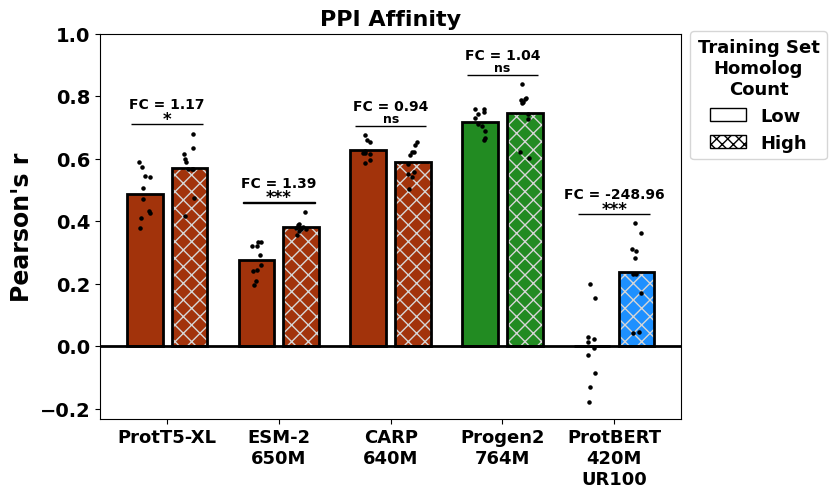

In [14]:
fig_E3d_c_data =  df.loc[
    (df["Task"] == "PPI Affinity") & 
    (df["Pool Method"] == "mean_pooled") & 
    (df["Training Setup"] == "Fine Tuned") 
]



x = []
y = []


data = []

x_counter = 0


color_list = []


green_models = [
    "Progen2 (2.7B) UR90+BFD30",
    "Progen2 (764M) UR90+BFD30",
    "ESM-1v"
]
blue_models = [
    "ProtBERT",
    "ESM-1 (670M) UR100"
]


x_position_list = []
y_position_list = []

fc_list = []

stars_list = []

label_list = []

y_offset = 0.03

for index, row in fig_E3d_c_data.iterrows():
    
    k = row["Model"]
    
    label_list.append(model_to_display_a[k])
    
   
    x1 = list(map(lambda x : float(x), row["Low Homolog Count Results"].split("|")))
    x2 = list(map(lambda x : float(x), row["High Homolog Count Results"].split("|")))
    
    st, p = scipy.stats.mannwhitneyu(x2, x1, alternative = "greater")
    stars_list.append(p_val_to_stars(p))
    
    
    m_1, ci_l_1, ci_h_1 = mean_confidence_interval(x1)
    
    x.append(x_counter)
    data.append(x1)
    y.append(m_1)
    
    x_counter += 1
    
    x_position_list.append(x_counter - 0.5)
    
    
    
    m_2, ci_l_2, ci_h_ = mean_confidence_interval(x2)
    
    y_position_list.append(max(np.max(x1), np.max(x2)) + y_offset)
    
    x.append(x_counter)
    data.append(x2)
    y.append(m_2)
    
    x_counter += 1
    x_counter += 0.5
    
    c = "#a2330b"
    if k in green_models:
        c = "forestgreen"
    elif k in blue_models:
        c = "dodgerblue"
        
    color_list.append(c)
    color_list.append(c)
    
    fc = m_2 / m_1
    
    fc_list.append(fc)
    
    

legend_handles = [
    mpatches.Patch(facecolor="white", edgecolor="black", label="Low", ),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch="xxx", label="High",)
]

    
fig, ax = plt.subplots(figsize = (1.5*len(label_list),5))


bars = ax.bar(
    x, 
    y,
    edgecolor = "black",
    color = color_list,
    linewidth = 2,
    hatch = ["", "xx"] * int((len(x) / 2))
)


# Flatten raw data
strip_x = []
strip_y = []

for xi, values in zip(x, data):
    strip_x.extend([xi] * len(values))
    strip_y.extend(values)

for xi, values in zip(x, data):
    jitter = np.random.uniform(-0.12, 0.12, len(values))

    ax.scatter(
        xi + jitter,
        values,
        color="black",
        s=5,
        zorder=10,
        marker = "o"
    )
    
for bar in bars:
    bar._hatch_color = to_rgba("#d6d6d6")  
    
for x_i, x_val in enumerate(x_position_list):
    y_val = y_position_list[x_i]
    rect = mpatches.Rectangle((x_val - 0.8, y_val), 1.6, 0.001, facecolor = "black", color = "black")
    ax.add_patch(rect)
    
    stars = stars_list[x_i]
    
    stars_fs = 12 if stars != "ns" else 9
    
    stars_offset = 0.012 if stars == "ns" else 0
    
    
    fc_str = str(round(fc_list[x_i], 2))
    ax.text(x_val, y_val + 0.05, "FC = " + fc_str, fontweight = "bold", horizontalalignment = "center") 
    
    ax.text(x_val, y_val  + stars_offset, stars, fontsize = stars_fs, fontweight = "bold", horizontalalignment = "center") 
    
    
ax.set_xticks(x_position_list)
ax.set_xticklabels(label_list, fontweight = "bold", fontsize = 13)
ax.set_xlim(left = np.min(x_position_list) - 1.5, right = np.max(x_position_list) + 1.5)

ax.set_yticks([-0.2, 0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(ax.get_yticklabels(), fontsize = 14, fontweight = "bold",)


ax.axhline(y = 0, color = "black", linewidth = 2)


ax.set_ylabel(f"Pearson's r", fontsize = 17, fontweight="bold" )

leg = ax.legend(
    handles=legend_handles,
    title="Training Set\nHomolog\nCount",
    loc="center left",
    bbox_to_anchor=(1, 0.84), 
    fontsize = 13,
    alignment="center",
    
)

legend_handles = [
    mpatches.Patch(facecolor="white", edgecolor="black", label="Low", ),
    mpatches.Patch(facecolor="white", edgecolor="black", hatch="xxx", label="High",)
]

leg.get_title().set_ha("center")
leg.get_title().set_fontweight("bold")
leg.get_title().set_fontsize(13)

for text in leg.get_texts():
    text.set_fontweight("bold")

ax.set_title("PPI Affinity", fontweight = "bold", fontsize = 16)



